# Самостоятельная работа: dense GAN на Fashion-MNIST

Здесь требуется самостоятельно перенести алгоритм состязательного
обучения на Fashion-MNIST. Данные отличаются от MNIST-примера, но
размер изображения, нормализация, архитектуры и математические цели
остаются теми же. Заголовки описывают этапы; маркеры «TODO(student)»
расположены только в кодовых ячейках.

Выполняйте задания строго по порядку. На каждом этапе сначала
подтвердите форму тензоров и только потом продолжайте. Метки классов
Fashion-MNIST не становятся целями GAN: задача по-прежнему состоит в
различении реального и синтетического изображения.

## История одного пакета

Генератор превращает пачку случайных карточек `(B,100)` в пачку
картинок `(B,784)`. Дискриминатор смотрит и на эти картинки, и на
настоящие предметы одежды, а затем выдаёт по одному числу `(B,1)`.
Сначала учится проверяющий, потом — художник. Выполняйте этапы именно
по порядку: следующий этап использует объекты, созданные и проверенные
на предыдущем.

### Маленький словарь перед реализацией

Параметры — обучаемые числа в слоях. Прямой проход создаёт картинку и
ответ проверяющего. Потеря — одно число, описывающее ошибку текущего
ответа. Градиент — инструкция, как слегка поменять параметры, чтобы
ошибка уменьшилась. `GradientTape` находит такую инструкцию, а Adam
применяет небольшую поправку.

## Этап 1. Конфигурация независимого эксперимента

**Доступно:** константы ниже. **Цель:** зафиксировать Fashion-MNIST,
первые 10 000 изображений, $d_z=100$, $d_x=784$, пакет 128 и
первоначальные 105 эпох. Для сравнений позднее установите 205 и 400
эпох, не меняя остальную постановку. **Контрольная точка:** диапазон
целевых меток GAN — 0.9, 0 и 1; это не метки предметов одежды.

`(B,784)` означает «B картинок, каждая записана длинной строкой из
784 яркостей», а `(B,1)` — один ответ проверяющего на картинку. Это не
784 разных объектов и не десять классов Fashion-MNIST.

In [1]:
from __future__ import annotations

# Path указывает только место для сеток и графиков. NumPy/Matplotlib
# обслуживают данные и диагностику; TensorFlow строит граф и модели.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Зафиксируйте seed до первого шума и создания слоёв, иначе два
# запуска нельзя будет сравнивать по одним и тем же условиям.
SEED = 42
DATASET_NAME = 'Fashion-MNIST'
MAX_EXAMPLES = 10_000
IMAGE_HEIGHT = 28
IMAGE_WIDTH = 28
# Размерность dense-входа: каждая карта 28×28 станет длиной 784.
IMAGE_DIM = IMAGE_HEIGHT * IMAGE_WIDTH
NOISE_DIM = 100
BATCH_SIZE = 128
EPOCHS = 105
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
FAKE_LABEL = 0.0
GENERATOR_TARGET = 1.0
SAVE_EVERY = 20

# Keras использует генератор случайных чисел и для весов, и для z.
tf.keras.utils.set_random_seed(SEED)
artifact_dir = Path('artifacts/fashion_mnist_dense_gan')
artifact_dir.mkdir(parents=True, exist_ok=True)

## Этап 2. Получение и подготовка Fashion-MNIST

**Требуется:** получить обучающие изображения Fashion-MNIST, оставить
первые 10 000, преобразовать пиксели из $[0,255]$ в $[-1,1]$ и
развернуть их в $(N,784)$. Затем создайте перемешиваемый набор
мини-пакетов $(B,784)$ без меток классов. **Проверьте:** значения
конечны и принадлежат $[-1,1]$; метки используются только для
необязательной подписи исходных изображений.

**Маршрут:** сначала загрузите массив и посмотрите на одну картинку,
затем приведите значения к `float32`, измените шкалу `[0,255] → [-1,1]`
и лишь потом разверните карту. Останавливайтесь на `assert`: при
неверной форме или диапазоне сеть строить ещё рано. `y_train` не
передаётся GAN, иначе это была бы задача классификации одежды.

In [2]:
# Вход этапа — внешний файл Fashion-MNIST. Получите x_train с формой
# (MAX_EXAMPLES, 28, 28) и y_train с формой (MAX_EXAMPLES,). y_train
# не включайте в Dataset: это имя одежды, а не ответ GAN.
# TODO(student): загрузите Fashion-MNIST и создайте x_train, y_train.
# Сначала приведите x_train к float32, затем одной линейной формулой
# переведите [0,255] в [-1,1] и только после этого разверните каждую
# карту 28×28 в вектор длины 784. Создайте dataset только из x_train:
# каждый его элемент до batching — один вектор (784,), после — (B,784).
# TODO(student): нормализуйте x_train, разверните изображения и создайте dataset.
# Контроль: x_train=(MAX_EXAMPLES,784), первый пакет=(BATCH_SIZE,784),
# все значения конечны и лежат в [-1,1].
# raise NotImplementedError('Реализуйте подготовку Fashion-MNIST.')

# Загружаем Fashion-MNIST из keras.datasets (скачивание при первом запуске).
(x_train_full, y_train_full), _ = tf.keras.datasets.fashion_mnist.load_data()

# Оставляем первые MAX_EXAMPLES изображений. Метки y_train оставляем только
# для необязательной подписи — в GAN они не передаются.
x_train = x_train_full[:MAX_EXAMPLES].astype("float32")
y_train = y_train_full[:MAX_EXAMPLES]

# [0,255] -> [-1,1] одной линейной формулой, затем разворачиваем 28x28 -> 784.
x_train = (x_train / 255.0) * 2.0 - 1.0
x_train = x_train.reshape(MAX_EXAMPLES, IMAGE_DIM)

# Dataset только из x_train: без меток классов.
dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(buffer_size=MAX_EXAMPLES, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

# Контрольные проверки.
assert x_train.shape == (MAX_EXAMPLES, IMAGE_DIM), x_train.shape
assert x_train.dtype == np.float32
assert np.isfinite(x_train).all()
assert x_train.min() >= -1.0 and x_train.max() <= 1.0
first_batch = next(iter(dataset))
assert first_batch.shape == (BATCH_SIZE, IMAGE_DIM), first_batch.shape
assert first_batch.dtype == tf.float32

print("x_train:", x_train.shape, "| диапазон:", (float(x_train.min()), float(x_train.max())))
print("первый пакет:", first_batch.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (10000, 784) | диапазон: (-1.0, 1.0)
первый пакет: (128, 784)


## Этап 3. Генератор и проверка его выхода

**Требуется:** собрать генератор
$100\to256\to512\to1024\to784$ с тремя LeakyReLU и финальным tanh.
Вход — шум $(B,100)$ с независимыми нормальными координатами; выход —
синтетические развёрнутые изображения $(B,784)$ в $[-1,1]$.
Используйте современный tf.keras и не применяйте готовый GAN-слой.
**Контрольная точка:** выход имеет точную форму и не содержит NaN или
бесконечностей.

Считайте `z` карточкой со 100 случайными ручками. В начале генератор
рисует бессмыслицу; обучение понемногу поправляет его веса, чтобы те
же 100 чисел превращались в структуру, похожую на данные. `tanh` не
даёт пикселям покинуть диапазон настоящих картинок.

In [3]:
# Фабрика не должна обучать сеть: она только создаёт независимый набор
# параметров θ_G. Input задаёт форму одного z_i=(100,), ось B не
# записывается. Dense-слои преобразуют (B,100) в (B,784); tanh нужен,
# чтобы диапазон синтеза был тем же [-1,1], что у настоящих данных.
# TODO(student): создайте initializer и функцию make_generator.
# После создания generator сформируйте z~N(0,I) формы (BATCH_SIZE,100)
# и вызовите G(z, training=False). Это диагностический прямой проход:
# не создавайте GradientTape и не вызывайте оптимизатор на этом этапе.
# TODO(student): постройте generator и проверьте G(z) на пакете шума.
# raise NotImplementedError('Реализуйте генератор Fashion-MNIST.')

def make_generator(seed: int = SEED) -> tf.keras.Model:
    initializer = tf.keras.initializers.GlorotUniform(seed=seed)
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(NOISE_DIM,)),
            tf.keras.layers.Dense(256, use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(512, use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(1024, use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            # Финальный tanh: диапазон синтеза совпадает с [-1,1] у реальных данных.
            tf.keras.layers.Dense(IMAGE_DIM, activation="tanh", kernel_initializer=initializer),
        ],
        name="generator",
    )


generator = make_generator()

# Диагностический прямой проход без GradientTape и без оптимизатора.
z_check = tf.random.normal((BATCH_SIZE, NOISE_DIM), seed=SEED)
generated_check = generator(z_check, training=False)

assert generated_check.shape == (BATCH_SIZE, IMAGE_DIM), generated_check.shape
assert np.isfinite(generated_check.numpy()).all()
print("G(z):", generated_check.shape, "| диапазон:", (float(tf.reduce_min(generated_check)), float(tf.reduce_max(generated_check))))

G(z): (128, 784) | диапазон: (-0.7468239665031433, 0.7138435244560242)


## Этап 4. Дискриминатор и смысл его выхода

**Требуется:** собрать дискриминатор
$784\to1024\to512\to256\to1$ с LeakyReLU, Dropout(0.3) и sigmoid.
Его входом по очереди будут настоящие и синтетические изображения
$(B,784)$, а результатом — $(B,1)$ вероятностей. Последняя координата
— не класс Fashion-MNIST, а оценка «настоящее».
**Контрольная точка:** на диагностическом входе значения строго между
0 и 1.

Единственный вопрос дискриминатора — «эта картинка пришла из набора
или создана генератором?». Его ответ после sigmoid можно читать как
уверенность от 0 до 1. Это совсем не вероятность одного из классов
одежды и не оценка того, насколько красив предмет.

In [4]:
# Здесь θ_D получает вектор изображения (B,784) и возвращает (B,1).
# Финальный sigmoid обязателен именно в этом варианте: BCE ниже будет
# получать вероятности и потому создаётся с from_logits=False. Dropout
# активен лишь при training=True, то есть в фазе обновления D.
# TODO(student): реализуйте make_discriminator и создайте discriminator.
# Для проверки пропустите через D как один реальный, так и один
# синтетический пакет. Убедитесь, что результат имеет форму (B,1),
# конечен и строго расположен между 0 и 1; это не класс одежды.
# TODO(student): проверьте форму D(x) и диапазон вероятностей.
# raise NotImplementedError('Реализуйте дискриминатор Fashion-MNIST.')

def make_discriminator(seed: int = SEED) -> tf.keras.Model:
    initializer = tf.keras.initializers.GlorotUniform(seed=seed)
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(IMAGE_DIM,)),
            tf.keras.layers.Dense(1024, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(512, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(256, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            # sigmoid -> вероятность "настоящее", а не класс одежды.
            tf.keras.layers.Dense(1, activation="sigmoid", kernel_initializer=initializer),
        ],
        name="discriminator",
    )


discriminator = make_discriminator()

# Диагностика: один реальный и один синтетический пакет.
real_check = next(iter(dataset))
fake_check = generator(tf.random.normal((BATCH_SIZE, NOISE_DIM), seed=SEED + 1), training=False)
real_scores_check = discriminator(real_check, training=False)
fake_scores_check = discriminator(fake_check, training=False)

assert real_scores_check.shape == (BATCH_SIZE, 1), real_scores_check.shape
assert fake_scores_check.shape == (BATCH_SIZE, 1), fake_scores_check.shape
assert np.isfinite(real_scores_check.numpy()).all()
assert np.isfinite(fake_scores_check.numpy()).all()
assert np.all(real_scores_check.numpy() > 0) and np.all(real_scores_check.numpy() < 1)
assert np.all(fake_scores_check.numpy() > 0) and np.all(fake_scores_check.numpy() < 1)
print("D(x_real):", real_scores_check.shape, "D(x_fake):", fake_scores_check.shape)

D(x_real): (128, 1) D(x_fake): (128, 1)


## Этап 5. Две функции потерь и два независимых обновления

**Требуется:** создать BinaryCrossentropy с «from_logits=False» и два
Adam-оптимизатора с заданными learning_rate и beta_1. Напишите
попеременный шаг: сначала обновляет только дискриминатор по настоящим
меткам 0.9 и синтетическим 0; затем обновляет только генератор по
цели 1. Для первого шага отделите синтетические изображения от
градиента генератора. Для второго вызовите дискриминатор с
«training=False», но сохраните прохождение градиента к генератору.

**Контрольная точка:** после первого подшага меняются только
переменные дискриминатора, после второго — только переменные
генератора. Обе потери должны быть конечными скалярами.

**Сначала → затем → проверить.** Сначала выполните фазу D и отделите
созданные картинки через `stop_gradient`: обратная стрелка к G
выключена. Затем создайте новый `GradientTape` для фазы G: стрелка от
ошибки идёт через D к G, но список параметров оптимизатора содержит
только G. Визуальная проверка проста: спросите, какие веса стоят справа
в каждом вызове `apply_gradients`.

Здесь D возвращает вероятность $p$ после sigmoid. Для одной цели $y$
API `BinaryCrossentropy(from_logits=False)` использует

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

Неправильный уверенный ответ получает большую потерю; правильный
уверенный ответ — малую. Для всего мини-пакета TensorFlow усредняет
эту ошибку, получая один скаляр для каждого игрока.

### Математический контракт вашей реализации

**Сначала посмотрите на две фазы глазами данных.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

Эта схема разделяет временные тензоры, скалярные потери и параметры.
Ваша будущая функция не должна пытаться «обучать шум» или метки
Fashion-MNIST: шум — вход, а метки классов вообще не участвуют в GAN.
Обучаемыми остаются только `tf.Variable` внутри G и D.

Обозначим веса и смещения генератора через $\theta_G$, а параметры
дискриминатора — через $\theta_D$. Потеря — один скаляр. Производная
по параметру показывает направление его маленькой поправки:

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В первой фазе для мини-пакета должны быть вычислены два члена
$\operatorname{BCE}(0.9,D(\mathbf x_{\rm real}))$ и
$\operatorname{BCE}(0,D(G(\mathbf z_D)))$; их среднее образует
$\mathcal L_D$, а градиент запрашивается только по $\theta_D$.
Во второй фазе $\mathcal L_G=\operatorname{BCE}(1,D(G(\mathbf z_G)))$
дифференцируется только по $\theta_G$. Шум — не параметр: каждый
$\mathbf z$ является новым входом формы `(B,100)`.

### Как `GradientTape` превращает loss в поправки весов

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`GradientTape` записывает прямой путь вычислений до `loss`, а не
делает отдельное обучение. Пока активен блок `with`, он помнит
дифференцируемые операции и автоматически наблюдает используемые
обучаемые `tf.Variable`. Затем `tape.gradient(loss, variables)`
запускает обратный проход и возвращает по одной производной для
каждого элемента `variables`; форма градиента совпадает с формой
веса. `zip` сопоставляет эти два списка, а `apply_gradients` передаёт
пары Adam. Именно `variables` определяет, обновляется $\theta_G$ или
$\theta_D$; имя tape этого решения не принимает.

Непостоянный tape имеет одно назначение: он нужен для одного вызова
`gradient`, затем его запись освобождается. Это программная запись
правила градиентного шага, а не эвристика TensorFlow. Производные
получаются по цепному правилу: библиотека не выписывает гигантские
якобианы, а передаёт их нужное действие от скалярной потери к весам.

### Один мини-пакет: карта объектов вашей реализации

Используйте эти имена как ориентиры при заполнении TODO. Объекты с
пометкой «временный» не являются параметрами и не передаются Adam.

| Математика | Ожидаемое имя | Форма | Роль в одной фазе |
| --- | --- | --- | --- |
| $\mathbf x_{\rm real}$ | `real_images` | `(B,784)`, `float32` | Настоящие картинки для D. |
| $\mathbf z_D$ | `discriminator_noise` | `(B,100)` | Временный шум фазы D. |
| $G(\mathbf z_D)$ | `fake_images` | `(B,784)` | Подделки после `stop_gradient`. |
| $D(\mathbf x)$ | `real_scores`, `fake_scores` | `(B,1)`, вероятность | Аргумент BCE фазы D. |
| $\mathcal L_D$ | `discriminator_loss` | скаляр | Даёт градиенты только для `discriminator.trainable_variables`. |
| $\mathbf z_G$ | `generator_noise` | `(B,100)` | Новый шум, независимый от $\mathbf z_D$. |
| $G(\mathbf z_G)$ | `generated_images` | `(B,784)` | Подделки, оставленные в графе. |
| $\mathcal L_G$ | `generator_loss` | скаляр | Даёт градиенты только для `generator.trainable_variables`. |

**Проведите одну фазу буквально по строкам.** Сначала внутри первого
`GradientTape` вычисляются входы D и один скаляр `discriminator_loss`.
Затем `tape.gradient(discriminator_loss,
discriminator.trainable_variables)` строит список производных в том же
порядке, что список весов. `zip` образует пары, и только после
`discriminator_optimizer.apply_gradients(...)` меняются $\theta_D$.
Фаза G повторяет эту схему с новым tape, новым шумом и списком весов G.

Для этой модели D выдаёт вероятность, поэтому точный путь градиента
генератора можно записать через якобианы:

$$
\nabla_{\theta_G}\mathcal L_G
=J_{G,\theta_G}^{\mathsf T}J_{D,\mathbf x}^{\mathsf T}
\nabla_{\mathbf p}\mathcal L_G.
$$

Якобиан — таблица всех локальных влияний: как выход меняется при малом
изменении входа. Он слишком велик для явного создания; `gradient`
вычисляет только нужный обратный проход, то есть произведения с ним.

In [5]:
# Сначала создайте BCE и ДВА Adam: состояния моментов G и D не могут
# быть общими. Затем определите train_step(real_images), где вход
# real_images имеет форму (B,784), а выход — два скаляра L_D и L_G.
# TODO(student): создайте bce, generator_optimizer и discriminator_optimizer.
# Фаза D: сформируйте z_D=(B,100), получите G(z_D, training=False),
# примените stop_gradient к изображениям, вычислите D(x_real) и
# D(x_fake), BCE с целями 0.9 и 0. После GradientTape запросите
# градиенты только по discriminator.trainable_variables и передайте
# именно эти пары второму оптимизатору.
# Фаза G: сформируйте независимый z_G, в новом GradientTape получите
# G(z_G, training=True) и D(G(z_G), training=False). training=False
# выключает Dropout D, но не обрывает производную к пикселям. Цель
# равна 1; gradient/apply_gradients получают только θ_G.
# TODO(student): реализуйте train_step через два GradientTape.
# Контроль: stop_gradient относится только к фазе D. Во второй фазе
# градиент должен идти L_G→D→G, хотя параметры D не обновляются.
# TODO(student): убедитесь, что каждый оптимизатор получает только свои переменные.
# raise NotImplementedError('Реализуйте попеременный шаг GAN.')

# BCE на вероятностях (после sigmoid), поэтому from_logits=False.
bce = tf.keras.losses.BinaryCrossentropy(from_logits=False)

# Два независимых Adam: состояния моментов G и D не смешиваются.
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)


@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    # ---------- Фаза D: обновляем только θ_D ----------
    discriminator_noise = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as disc_tape:
        # stop_gradient: обратная стрелка к G выключена в фазе D.
        fake_images = tf.stop_gradient(generator(discriminator_noise, training=False))

        real_scores = discriminator(real_images, training=True)
        fake_scores = discriminator(fake_images, training=True)

        real_loss = bce(tf.fill((batch_size, 1), REAL_LABEL), real_scores)
        fake_loss = bce(tf.fill((batch_size, 1), FAKE_LABEL), fake_scores)
        discriminator_loss = 0.5 * (real_loss + fake_loss)

    disc_grads = disc_tape.gradient(discriminator_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(
        zip(disc_grads, discriminator.trainable_variables)
    )

    # ---------- Фаза G: обновляем только θ_G ----------
    generator_noise = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as gen_tape:
        generated_images = generator(generator_noise, training=True)
        # training=False выключает Dropout D, но не обрывает градиент к G.
        generated_scores = discriminator(generated_images, training=False)
        generator_loss = bce(tf.fill((batch_size, 1), GENERATOR_TARGET), generated_scores)

    gen_grads = gen_tape.gradient(generator_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gen_grads, generator.trainable_variables))

    return discriminator_loss, generator_loss


# Контроль: один шаг на реальном пакете, потери — конечные скаляры.
sample_batch = next(iter(dataset))
d_loss, g_loss = train_step(sample_batch)
assert np.isfinite(d_loss.numpy()) and np.isfinite(g_loss.numpy())
assert d_loss.shape == () and g_loss.shape == ()
print(f"один шаг: L_D={float(d_loss):.4f}, L_G={float(g_loss):.4f}")

один шаг: L_D=0.7076, L_G=0.7006


## Этап 6. Эксперименты, сетки и отчёт

**Требуется:** обучите GAN сначала 105 эпох. На фиксированных 100
шумовых векторах сохраните сетки после первой эпохи, далее через
равные интервалы и в конце. Постройте отдельные ряды потерь
дискриминатора и генератора. Затем повторите запуск для 205 и 400 эпох
с теми же архитектурой, шумом, размером выборки и способом
визуализации.

**Проверка:** все значения потерь конечны; формы не меняются;
изображения становятся разнообразнее или обнаруживаются и
объясняются признаки неустойчивости. В отчёте сравните три режима, не
объявляя меньшую потерю одной стороны безусловной победой GAN.

Фиксированный шум — одинаковый набор заданий для художника. Показывая
его после нескольких эпох, вы видите изменение весов, а не новую
случайную карточку. Для Matplotlib значения возвращаются из `[-1,1]`
в `[0,1]`: модель при этом не меняется. Кривые потерь читайте вместе с
сетками, потому что GAN — соревнование, а не одна убывающая ошибка.

[run105] эпоха   1/105 | L_D=0.5604 | L_G=1.0221
[run105] эпоха  10/105 | L_D=0.5687 | L_G=1.4269
[run105] эпоха  20/105 | L_D=0.5853 | L_G=1.3812
[run105] эпоха  30/105 | L_D=0.6011 | L_G=1.3085
[run105] эпоха  40/105 | L_D=0.6310 | L_G=1.1096
[run105] эпоха  50/105 | L_D=0.6390 | L_G=1.0957
[run105] эпоха  60/105 | L_D=0.6469 | L_G=1.0388
[run105] эпоха  70/105 | L_D=0.6502 | L_G=1.0382
[run105] эпоха  80/105 | L_D=0.6519 | L_G=1.0439
[run105] эпоха  90/105 | L_D=0.6557 | L_G=1.0374
[run105] эпоха 100/105 | L_D=0.6589 | L_G=1.0210
[run105] эпоха 105/105 | L_D=0.6608 | L_G=1.0150
[run205] эпоха   1/205 | L_D=0.6630 | L_G=1.0111
[run205] эпоха  10/205 | L_D=0.6602 | L_G=1.0143
[run205] эпоха  20/205 | L_D=0.6599 | L_G=1.0139
[run205] эпоха  30/205 | L_D=0.6640 | L_G=1.0077
[run205] эпоха  40/205 | L_D=0.6633 | L_G=1.0142
[run205] эпоха  50/205 | L_D=0.6631 | L_G=1.0077
[run205] эпоха  60/205 | L_D=0.6641 | L_G=1.0076
[run205] эпоха  70/205 | L_D=0.6621 | L_G=1.0097
[run205] эпоха  80/2

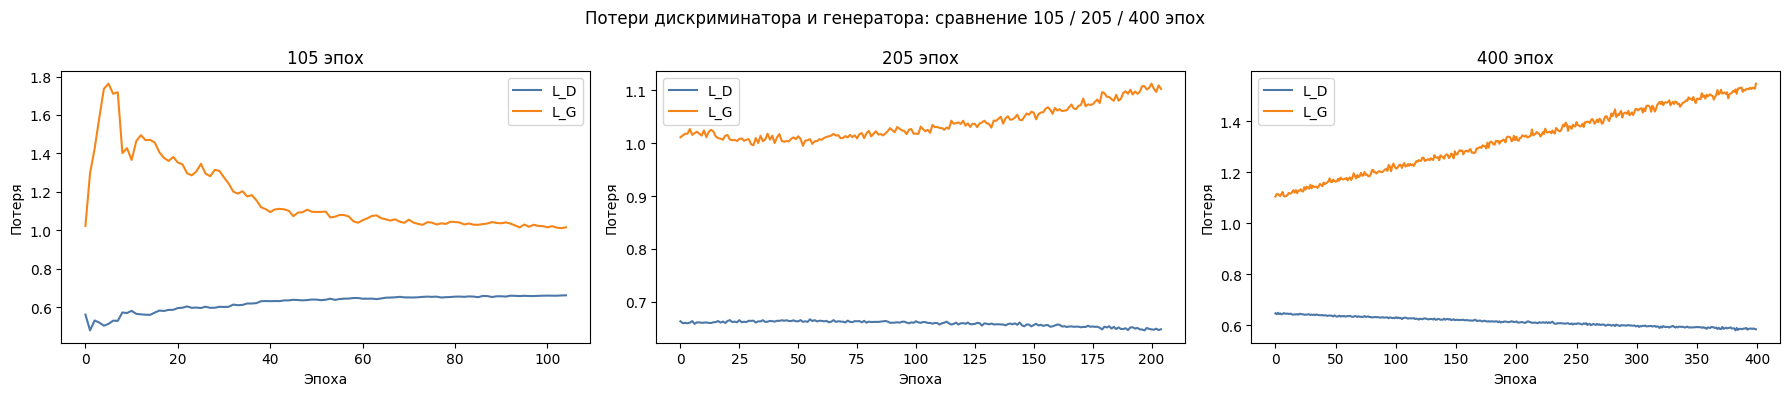

Сохранено в: artifacts\fashion_mnist_dense_gan


In [6]:
# Внешний цикл вызывает train_step для каждого реального мини-пакета.
# Преобразуйте возвращённые скаляры в числа только ПОСЛЕ выхода из
# tf.function, усредните их по эпохе и добавьте в history. Иначе
# граф TensorFlow смешается с диагностическим кодом NumPy/Matplotlib.
# TODO(student): реализуйте обучение по эпохам, history и сохранение сеток.
# fixed_noise=(100,100) создаётся один раз до цикла. Для снимка вызовите
# G(fixed_noise, training=False), измените [-1,1] на [0,1], разверните
# в (100,28,28) и явно задайте vmin=0, vmax=1. Повторите запуски на
# 105, 205, 400 эпохах, меняя только EPOCHS.
# TODO(student): постройте график двух потерь и выполните сравнение 105, 205, 400 эпох.
# raise NotImplementedError('Реализуйте эксперименты Fashion-MNIST.')

# Фиксированный шум создаётся один раз: один и тот же набор заданий художнику.
fixed_noise = tf.random.normal((100, NOISE_DIM), seed=SEED)


def make_grid(model, noise, path):
    samples = model(noise, training=False)
    samples = (samples + 1.0) / 2.0  # [-1,1] -> [0,1]
    samples = tf.reshape(samples, (-1, IMAGE_HEIGHT, IMAGE_WIDTH))
    fig, axes = plt.subplots(10, 10, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        ax.imshow(samples[i], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(f"Сетка 10×10, эпоха {path.stem.split('_')[-1]}")
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)


def run_experiment(epochs: int, tag: str):
    # Полный перезапуск: новые веса и новые оптимизаторы — сравнение честное.
    tf.keras.utils.set_random_seed(SEED)
    global generator, discriminator, generator_optimizer, discriminator_optimizer
    generator = make_generator()
    discriminator = make_discriminator()
    generator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)
    discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)

    history = {"d_loss": [], "g_loss": []}
    grid_epochs = {1} | set(range(SAVE_EVERY, epochs + 1, SAVE_EVERY)) | {epochs}

    for epoch in range(1, epochs + 1):
        d_epoch, g_epoch, n_batches = [], [], 0
        for real_batch in dataset:
            d_loss, g_loss = train_step(real_batch)
            # Скаляры в числа — только после выхода из tf.function.
            d_epoch.append(float(d_loss))
            g_epoch.append(float(g_loss))
            n_batches += 1
        history["d_loss"].append(float(np.mean(d_epoch)))
        history["g_loss"].append(float(np.mean(g_epoch)))

        if epoch in grid_epochs:
            make_grid(generator, fixed_noise, artifact_dir / f"grid_{tag}_epoch_{epoch:03d}.png")
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f"[{tag}] эпоха {epoch:3d}/{epochs} | L_D={history['d_loss'][-1]:.4f} | L_G={history['g_loss'][-1]:.4f}")

    assert all(np.isfinite(v) for v in history["d_loss"] + history["g_loss"])
    return history


# Три запуска: 105, 205, 400 эпох. Меняется только EPOCHS.
all_histories = {}
for run_epochs in (105, 205, 400):
    all_histories[run_epochs] = run_experiment(run_epochs, tag=f"run{run_epochs}")

# График двух потерь для каждого запуска.
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (run_epochs, hist) in zip(axes, all_histories.items()):
    ax.plot(hist["d_loss"], label="L_D", color="#4c78a8")
    ax.plot(hist["g_loss"], label="L_G", color="#f58518")
    ax.set_title(f"{run_epochs} эпох")
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Потеря")
    ax.legend()
fig.suptitle("Потери дискриминатора и генератора: сравнение 105 / 205 / 400 эпох")
fig.tight_layout()
fig.savefig(artifact_dir / "loss_curves_105_205_400.png", dpi=110)
plt.show()

print("Сохранено в:", artifact_dir)

**Замечания по интерпретации результатов**

Меньшая потеря одной стороны не означает победу GAN: это соревнование, а не одна убывающая ошибка. Кривые L_D и L_G нужно читать вместе с сетками.

Если после 205/400 эпох видно mode collapse (все 100 снимков почти одинаковы) или нестабильность (L_D/L_G скачут, NaN/inf — исключены assert), это следует зафиксировать в отчёте как наблюдаемый признак, а не «успех».

Фиксированный fixed_noise — одинаковый набор заданий для художника, поэтому рост разнообразия сетки между эпохами отражает изменение весов G, а не новую случайную карточку.

## Этап 7. Итоговая самопроверка

- Использован именно Fashion-MNIST, а не MNIST из примера.
- Шум имеет форму $(B,100)$; реальные и синтетические изображения —
  $(B,784)$; ответ дискриминатора — $(B,1)$.
- Реальные значения нормированы к $[-1,1]$, как и выход tanh
  генератора.
- Метки классов одежды не входят в BinaryCrossentropy GAN.
- Генератор и дискриминатор обновляются отдельными оптимизаторами.
- Сетки и две истории потерь сохранены для всех трёх экспериментов.